In [1]:
import requests
import pandas as pd
from bs4 import BeautifulSoup
from pathlib import Path

# Project folder
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Stripe public Greenhouse job-board API
API_URL = (
    "https://boards-api.greenhouse.io/v1/"
    "boards/stripe/jobs?content=true"
)

response = requests.get(
    API_URL,
    timeout=30,
    headers={"User-Agent": "JobMarketAnalytics/1.0"}
)

response.raise_for_status()

data = response.json()
jobs = data.get("jobs", [])

print("API connection successful!")
print("Total job postings retrieved:", len(jobs))
print("Available response keys:", list(data.keys()))

API connection successful!
Total job postings retrieved: 720
Available response keys: ['jobs', 'meta']


In [2]:
if jobs:
    print("First job posting:")
    print(jobs[0].keys())

    print("\nJob title:")
    print(jobs[0].get("title"))

    print("\nLocation:")
    print(jobs[0].get("location"))

    print("\nJob URL:")
    print(jobs[0].get("absolute_url"))
else:
    print("No job postings returned. Check the API response.")

First job posting:
dict_keys(['absolute_url', 'data_compliance', 'education', 'internal_job_id', 'location', 'metadata', 'id', 'updated_at', 'requisition_id', 'title', 'company_name', 'first_published', 'language', 'application_deadline', 'content', 'departments', 'offices', 'ai_disclaimer', 'include_ai_disclaimer', 'ai_opt_out_request_url'])

Job title:
Abuse Investigator

Location:
{'name': 'Seattle, San Francisco, New York City'}

Job URL:
https://stripe.com/jobs/search?gh_jid=8172510


In [3]:
records = []

for job in jobs:
    # Extract readable job description
    html_description = job.get("content") or ""
    soup = BeautifulSoup(html_description, "html.parser")
    description_text = soup.get_text(" ", strip=True)

    # Extract departments and offices
    departments = [
        item.get("name", "")
        for item in job.get("departments", [])
    ]

    offices = [
        item.get("name", "")
        for item in job.get("offices", [])
    ]

    location = job.get("location") or {}

    records.append({
        "job_id": job.get("id"),
        "job_title": job.get("title"),
        "department": ", ".join(departments),
        "location": location.get("name", ""),
        "office": ", ".join(offices),
        "date_updated": job.get("updated_at"),
        "job_url": job.get("absolute_url"),
        "job_description": description_text
    })

df = pd.DataFrame(records)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (720, 8)


,job_id,job_title,department,location,office,date_updated,job_url,job_description
0,8172510,Abuse Investigator,8611 Security Analytics,"Seattle, San Francisco, New York City",US,2026-10-22T09:17:09-04:00,https://stripe.com/jobs/search?gh_jid=8172510,<h2><strong>Who we are </strong></h2>\n<h3><st...
1,8172508,Abuse Investigator,8611 Security Analytics,Dublin,Ireland Locations,2026-10-22T09:16:15-04:00,https://stripe.com/jobs/search?gh_jid=8172508,<h2><strong>Who we are </strong></h2>\n<h3><st...
2,8172487,Abuse Investigator,8611 Security Analytics,Dublin,Ireland Locations,2026-10-22T09:16:14-04:00,https://stripe.com/jobs/search?gh_jid=8172487,<h2><strong>Who we are </strong></h2>\n<h3><st...
3,8172503,Abuse Research Engineer,8611 Security Analytics,Remote from the US,US,2026-10-22T09:17:09-04:00,https://stripe.com/jobs/search?gh_jid=8172503,<h2>Who we are</h2>\n<h3>About Stripe</h3>\n<p...
4,8138044,"Account Executive, AI Sales",1654 Account Executives (AI),"San Francisco, CA",US,2026-10-22T09:17:07-04:00,https://stripe.com/jobs/search?gh_jid=8138044,"<div class=""JobPostPage-content ⚙ ⚙1opjj73"">\n..."


In [4]:
raw_file = DATA_DIR / "Stripe_Job_Postings_Raw.csv"

df.to_csv(raw_file, index=False, encoding="utf-8-sig")

print("Raw dataset saved to:", raw_file.resolve())
print("Rows:", len(df))
print("Columns:", len(df.columns))

Raw dataset saved to: /content/data/Stripe_Job_Postings_Raw.csv
Rows: 720
Columns: 8


In [6]:
from google.colab import files

files.download('/content/data/Stripe_Job_Postings_Raw.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
from google.colab import files

uploaded = files.upload()

Saving Stripe_Job_Postings_Raw.csv to Stripe_Job_Postings_Raw.csv


In [8]:
import pandas as pd
import numpy as np

df = pd.read_csv("Stripe_Job_Postings_Raw.csv")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Rows: 720
Columns: 8


,job_id,job_title,department,location,office,date_updated,job_url,job_description
0,8172510,Abuse Investigator,8611 Security Analytics,"Seattle, San Francisco, New York City",US,2026-10-22T09:17:09-04:00,https://stripe.com/jobs/search?gh_jid=8172510,<h2><strong>Who we are </strong></h2>\n<h3><st...
1,8172508,Abuse Investigator,8611 Security Analytics,Dublin,Ireland Locations,2026-10-22T09:16:15-04:00,https://stripe.com/jobs/search?gh_jid=8172508,<h2><strong>Who we are </strong></h2>\n<h3><st...
2,8172487,Abuse Investigator,8611 Security Analytics,Dublin,Ireland Locations,2026-10-22T09:16:14-04:00,https://stripe.com/jobs/search?gh_jid=8172487,<h2><strong>Who we are </strong></h2>\n<h3><st...
3,8172503,Abuse Research Engineer,8611 Security Analytics,Remote from the US,US,2026-10-22T09:17:09-04:00,https://stripe.com/jobs/search?gh_jid=8172503,<h2>Who we are</h2>\n<h3>About Stripe</h3>\n<p...
4,8138044,"Account Executive, AI Sales",1654 Account Executives (AI),"San Francisco, CA",US,2026-10-22T09:17:07-04:00,https://stripe.com/jobs/search?gh_jid=8138044,"<div class=""JobPostPage-content ⚙ ⚙1opjj73"">\n..."


In [9]:
# Column names and data types
df.info()

# Missing values in each column
print("\nMissing values:")
display(df.isnull().sum())

# Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Duplicate job IDs
if "job_id" in df.columns:
    print("Duplicate job IDs:", df["job_id"].duplicated().sum())

# Basic dataset statistics
display(df.describe(include="all").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   job_id           720 non-null    int64 
 1   job_title        720 non-null    object
 2   department       720 non-null    object
 3   location         701 non-null    object
 4   office           720 non-null    object
 5   date_updated     720 non-null    object
 6   job_url          720 non-null    object
 7   job_description  720 non-null    object
dtypes: int64(1), object(7)
memory usage: 45.1+ KB

Missing values:


,0
job_id,0
job_title,0
department,0
location,19
office,0
date_updated,0
job_url,0
job_description,0



Duplicate rows: 0
Duplicate job IDs: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
job_id,720.0,NaN,NaN,NaN,8058849.8875,333420.567796,5416444.0,8048092.5,8171157.5,8220933.5,8314283.0
job_title,720,661,"Software Engineer, New Grad",7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
department,720,209,1185 Account Executives (EMEA),34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location,701,290,Singapore,48,NaN,NaN,NaN,NaN,NaN,NaN,NaN
office,720,41,US,353,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_updated,720,73,2026-10-21T14:53:01-04:00,142,NaN,NaN,NaN,NaN,NaN,NaN,NaN
job_url,720,720,https://stripe.com/jobs/search?gh_jid=8045862,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
job_description,720,689,<h2><strong>Who we are</strong></h2>\n<h3><str...,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
# Create a copy so the original DataFrame stays unchanged
cleaned_df = df.copy()

# Remove accidental leading/trailing spaces from column names
cleaned_df.columns = cleaned_df.columns.str.strip()

# Standardize text fields
text_columns = cleaned_df.select_dtypes(
    include=["object", "string"]
).columns

for col in text_columns:
    cleaned_df[col] = cleaned_df[col].map(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Treat empty strings as missing values
cleaned_df.replace(r"^\s*$", np.nan, regex=True, inplace=True)

# Remove duplicate rows
cleaned_df.drop_duplicates(inplace=True)

# Remove duplicate job IDs, keeping the first occurrence
if "job_id" in cleaned_df.columns:
    cleaned_df = cleaned_df.drop_duplicates(
        subset=["job_id"], keep="first"
    )

# Reset row numbering
cleaned_df.reset_index(drop=True, inplace=True)

print("Cleaning completed!")
print("Original shape:", df.shape)
print("Cleaned shape:", cleaned_df.shape)

display(cleaned_df.head())

Cleaning completed!
Original shape: (720, 8)
Cleaned shape: (720, 8)


,job_id,job_title,department,location,office,date_updated,job_url,job_description
0,8172510,Abuse Investigator,8611 Security Analytics,"Seattle, San Francisco, New York City",US,2026-10-22T09:17:09-04:00,https://stripe.com/jobs/search?gh_jid=8172510,<h2><strong>Who we are </strong></h2>\n<h3><st...
1,8172508,Abuse Investigator,8611 Security Analytics,Dublin,Ireland Locations,2026-10-22T09:16:15-04:00,https://stripe.com/jobs/search?gh_jid=8172508,<h2><strong>Who we are </strong></h2>\n<h3><st...
2,8172487,Abuse Investigator,8611 Security Analytics,Dublin,Ireland Locations,2026-10-22T09:16:14-04:00,https://stripe.com/jobs/search?gh_jid=8172487,<h2><strong>Who we are </strong></h2>\n<h3><st...
3,8172503,Abuse Research Engineer,8611 Security Analytics,Remote from the US,US,2026-10-22T09:17:09-04:00,https://stripe.com/jobs/search?gh_jid=8172503,<h2>Who we are</h2>\n<h3>About Stripe</h3>\n<p...
4,8138044,"Account Executive, AI Sales",1654 Account Executives (AI),"San Francisco, CA",US,2026-10-22T09:17:07-04:00,https://stripe.com/jobs/search?gh_jid=8138044,"<div class=""JobPostPage-content ⚙ ⚙1opjj73"">\n..."


In [11]:
cleaned_file = "Stripe_Job_Postings_Cleaned.csv"

cleaned_df.to_csv(cleaned_file, index=False, encoding="utf-8-sig")

print("Cleaned file saved:", cleaned_file)

Cleaned file saved: Stripe_Job_Postings_Cleaned.csv


In [12]:
import pandas as pd
import numpy as np
import re

df = pd.read_csv("Stripe_Job_Postings_Cleaned.csv")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head(3))

Dataset shape: (720, 8)
Columns: ['job_id', 'job_title', 'department', 'location', 'office', 'date_updated', 'job_url', 'job_description']


,job_id,job_title,department,location,office,date_updated,job_url,job_description
0,8172510,Abuse Investigator,8611 Security Analytics,"Seattle, San Francisco, New York City",US,2026-10-22T09:17:09-04:00,https://stripe.com/jobs/search?gh_jid=8172510,<h2><strong>Who we are </strong></h2>\n<h3><st...
1,8172508,Abuse Investigator,8611 Security Analytics,Dublin,Ireland Locations,2026-10-22T09:16:15-04:00,https://stripe.com/jobs/search?gh_jid=8172508,<h2><strong>Who we are </strong></h2>\n<h3><st...
2,8172487,Abuse Investigator,8611 Security Analytics,Dublin,Ireland Locations,2026-10-22T09:16:14-04:00,https://stripe.com/jobs/search?gh_jid=8172487,<h2><strong>Who we are </strong></h2>\n<h3><st...


In [13]:
# Work on a separate copy
features_df = df.copy()

# 1. Standardize text fields
for col in ["job_title", "department", "location",
            "office", "job_description"]:
    if col in features_df.columns:
        features_df[col] = features_df[col].fillna("").astype(str).str.strip()

# 2. Extract job title in lowercase for classification
features_df["job_title_lower"] = (
    features_df["job_title"].str.lower()
)

# 3. Classify job function using job titles
def classify_job(title):
    title = title.lower()

    if any(x in title for x in ["data scientist", "machine learning", "ai engineer"]):
        return "AI / Machine Learning"
    elif any(x in title for x in ["data analyst", "analytics engineer", "business intelligence"]):
        return "Data Analytics"
    elif any(x in title for x in ["data engineer", "data platform"]):
        return "Data Engineering"
    elif any(x in title for x in ["software engineer", "developer", "frontend", "backend"]):
        return "Software Engineering"
    elif any(x in title for x in ["product manager", "product designer"]):
        return "Product"
    elif any(x in title for x in ["security", "information security"]):
        return "Security"
    elif any(x in title for x in ["sales", "account executive", "business development"]):
        return "Sales / Business Development"
    elif any(x in title for x in ["recruiter", "human resources", "people partner"]):
        return "Human Resources"
    elif any(x in title for x in ["finance", "accountant", "controller"]):
        return "Finance"
    elif any(x in title for x in ["marketing", "communications"]):
        return "Marketing"
    elif any(x in title for x in ["intern", "internship"]):
        return "Internship"
    else:
        return "Other"

features_df["job_category"] = features_df["job_title"].apply(classify_job)

# 4. Estimate seniority from job title
def classify_seniority(title):
    title = title.lower()

    if "intern" in title:
        return "Intern"
    elif any(x in title for x in ["chief", "vice president", "vp ", "director"]):
        return "Executive / Director"
    elif any(x in title for x in ["staff", "principal", "distinguished"]):
        return "Staff / Principal"
    elif "senior" in title or "sr." in title:
        return "Senior"
    elif "lead" in title or "manager" in title:
        return "Lead / Manager"
    elif "junior" in title or "entry level" in title:
        return "Entry Level"
    else:
        return "Unspecified"

features_df["seniority_level"] = features_df["job_title"].apply(
    classify_seniority
)

# 5. Estimate location type using available text
def classify_location(row):
    text = " ".join([
        str(row.get("location", "")),
        str(row.get("office", ""))
    ]).lower()

    if "remote" in text:
        return "Remote"
    elif "hybrid" in text:
        return "Hybrid"
    elif text.strip():
        return "Location Listed"
    else:
        return "Not Specified"

features_df["location_type"] = features_df.apply(
    classify_location, axis=1
)

# 6. Extract update date
if "date_updated" in features_df.columns:
    features_df["date_updated"] = pd.to_datetime(
        features_df["date_updated"], errors="coerce", utc=True
    )

    features_df["updated_year"] = (
        features_df["date_updated"].dt.year
    )

    features_df["updated_month"] = (
        features_df["date_updated"].dt.month
    )

print("Feature engineering completed!")
display(features_df.head())

Feature engineering completed!


,job_id,job_title,department,location,office,date_updated,job_url,job_description,job_title_lower,job_category,seniority_level,location_type,updated_year,updated_month
0,8172510,Abuse Investigator,8611 Security Analytics,"Seattle, San Francisco, New York City",US,2026-10-22 13:17:09+00:00,https://stripe.com/jobs/search?gh_jid=8172510,<h2><strong>Who we are </strong></h2>\n<h3><st...,abuse investigator,Other,Unspecified,Location Listed,2026,10
1,8172508,Abuse Investigator,8611 Security Analytics,Dublin,Ireland Locations,2026-10-22 13:16:15+00:00,https://stripe.com/jobs/search?gh_jid=8172508,<h2><strong>Who we are </strong></h2>\n<h3><st...,abuse investigator,Other,Unspecified,Location Listed,2026,10
2,8172487,Abuse Investigator,8611 Security Analytics,Dublin,Ireland Locations,2026-10-22 13:16:14+00:00,https://stripe.com/jobs/search?gh_jid=8172487,<h2><strong>Who we are </strong></h2>\n<h3><st...,abuse investigator,Other,Unspecified,Location Listed,2026,10
3,8172503,Abuse Research Engineer,8611 Security Analytics,Remote from the US,US,2026-10-22 13:17:09+00:00,https://stripe.com/jobs/search?gh_jid=8172503,<h2>Who we are</h2>\n<h3>About Stripe</h3>\n<p...,abuse research engineer,Other,Unspecified,Remote,2026,10
4,8138044,"Account Executive, AI Sales",1654 Account Executives (AI),"San Francisco, CA",US,2026-10-22 13:17:07+00:00,https://stripe.com/jobs/search?gh_jid=8138044,"<div class=""JobPostPage-content ⚙ ⚙1opjj73"">\n...","account executive, ai sales",Sales / Business Development,Unspecified,Location Listed,2026,10


In [14]:
# Skills to investigate
skills = [
    "Python", "SQL", "Java", "C++", "JavaScript",
    "TypeScript", "AWS", "Azure", "GCP",
    "Docker", "Kubernetes", "Machine Learning",
    "Power BI", "Tableau", "Excel",
    "Pandas", "Spark", "Hadoop",
    "React", "Node.js", "Go", "Ruby",
    "Data Analysis", "Statistics", "ETL",
    "Snowflake", "PostgreSQL", "MySQL"
]

# Combine text fields for searching
search_text = (
    features_df.get("job_title", "").astype(str)
    + " "
    + features_df.get("department", "").astype(str)
    + " "
    + features_df.get("job_description", "").astype(str)
).str.lower()

# Create one indicator column per skill
for skill in skills:
    pattern = re.escape(skill.lower())

    # Word boundaries help avoid matching partial words
    features_df[f"skill_{re.sub(r'[^A-Za-z0-9]+', '_', skill).strip('_').lower()}"] = (
        search_text.str.contains(pattern, regex=True, na=False).astype(int)
    )

print("Skill indicators created!")

Skill indicators created!


In [15]:
skill_columns = [
    col for col in features_df.columns
    if col.startswith("skill_")
]

skill_summary = (
    features_df[skill_columns]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

skill_summary.columns = ["skill_column", "job_postings_mentioning_skill"]

skill_summary["skill"] = (
    skill_summary["skill_column"]
    .str.replace("skill_", "", regex=False)
    .str.replace("_", " ", regex=False)
    .str.title()
)

skill_summary = skill_summary[
    ["skill", "job_postings_mentioning_skill"]
]

print("Most frequently mentioned skills:")
display(skill_summary.head(15))

Most frequently mentioned skills:


,skill,job_postings_mentioning_skill
0,Go,596
1,Excel,301
2,Sql,150
3,Python,87
4,Java,72
5,Ruby,67
6,Aws,50
7,Machine Learning,35
8,Javascript,34
9,Spark,31


In [16]:
print("Rows:", features_df.shape[0])
print("Columns:", features_df.shape[1])
print("Duplicate job IDs:", (
    features_df["job_id"].duplicated().sum()
    if "job_id" in features_df.columns else "Column unavailable"
))

features_df.to_csv(
    "Stripe_Job_Postings_Featured.csv",
    index=False,
    encoding="utf-8-sig"
)

skill_summary.to_csv(
    "Stripe_Skill_Summary.csv",
    index=False,
    encoding="utf-8-sig"
)

from google.colab import files

files.download("Stripe_Job_Postings_Featured.csv")
files.download("Stripe_Skill_Summary.csv")

Rows: 720
Columns: 42
Duplicate job IDs: 0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Stripe_Job_Postings_Featured.csv")

print("Dataset shape:", df.shape)
print("Total job postings:", len(df))

display(df.head())

Dataset shape: (720, 42)
Total job postings: 720


,job_id,job_title,department,location,office,date_updated,job_url,job_description,job_title_lower,job_category,...,skill_react,skill_node_js,skill_go,skill_ruby,skill_data_analysis,skill_statistics,skill_etl,skill_snowflake,skill_postgresql,skill_mysql
0,8172510,Abuse Investigator,8611 Security Analytics,"Seattle, San Francisco, New York City",US,2026-10-22 13:17:09+00:00,https://stripe.com/jobs/search?gh_jid=8172510,<h2><strong>Who we are </strong></h2>\n<h3><st...,abuse investigator,Other,...,0,0,1,0,0,0,0,0,0,0
1,8172508,Abuse Investigator,8611 Security Analytics,Dublin,Ireland Locations,2026-10-22 13:16:15+00:00,https://stripe.com/jobs/search?gh_jid=8172508,<h2><strong>Who we are </strong></h2>\n<h3><st...,abuse investigator,Other,...,0,0,1,0,0,0,0,0,0,0
2,8172487,Abuse Investigator,8611 Security Analytics,Dublin,Ireland Locations,2026-10-22 13:16:14+00:00,https://stripe.com/jobs/search?gh_jid=8172487,<h2><strong>Who we are </strong></h2>\n<h3><st...,abuse investigator,Other,...,0,0,1,0,0,0,0,0,0,0
3,8172503,Abuse Research Engineer,8611 Security Analytics,Remote from the US,US,2026-10-22 13:17:09+00:00,https://stripe.com/jobs/search?gh_jid=8172503,<h2>Who we are</h2>\n<h3>About Stripe</h3>\n<p...,abuse research engineer,Other,...,1,0,0,0,0,0,0,0,0,0
4,8138044,"Account Executive, AI Sales",1654 Account Executives (AI),"San Francisco, CA",US,2026-10-22 13:17:07+00:00,https://stripe.com/jobs/search?gh_jid=8138044,"<div class=""JobPostPage-content ⚙ ⚙1opjj73"">\n...","account executive, ai sales",Sales / Business Development,...,0,0,1,0,0,0,0,0,0,0


,count
job_category,
Other,334
Sales / Business Development,157
Software Engineering,82
Product,45
Marketing,32
Security,16
AI / Machine Learning,15
Finance,12
Human Resources,11


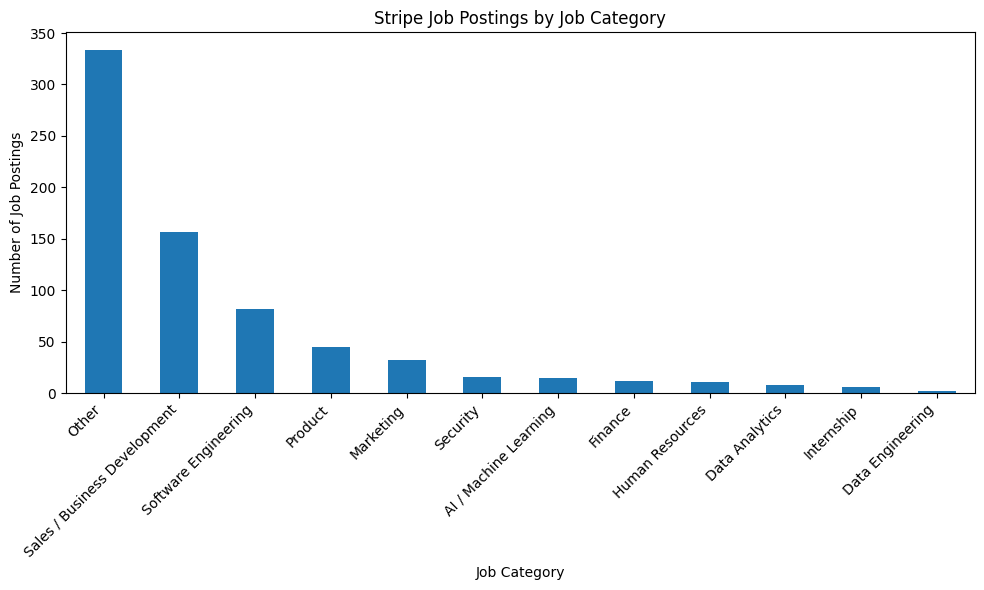

In [18]:
category_counts = df["job_category"].value_counts()

display(category_counts)

plt.figure(figsize=(10, 6))
category_counts.plot(kind="bar")
plt.title("Stripe Job Postings by Job Category")
plt.xlabel("Job Category")
plt.ylabel("Number of Job Postings")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

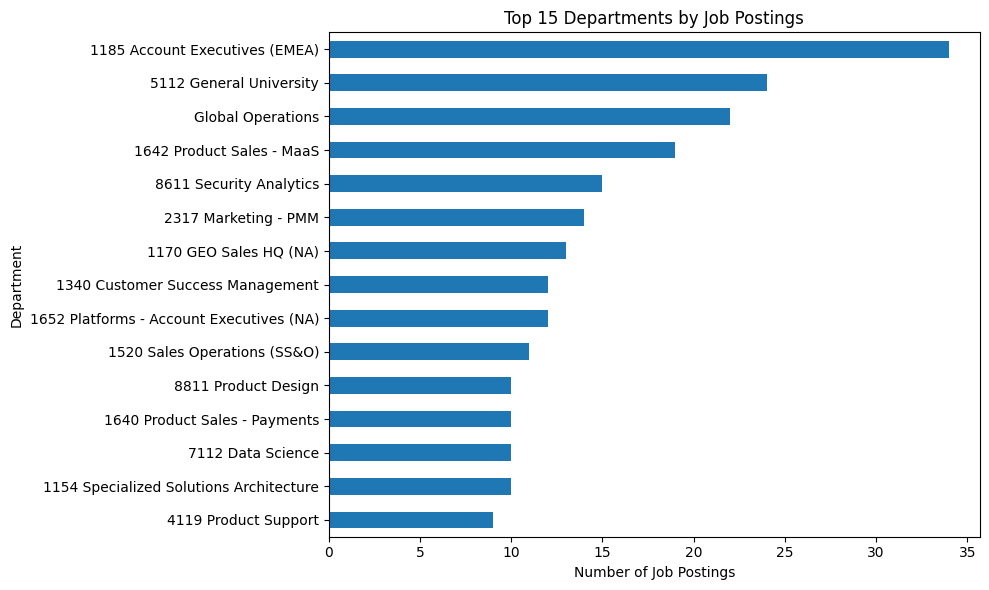

In [19]:
department_counts = (
    df["department"]
    .replace("", "Not Specified")
    .value_counts()
    .head(15)
)

plt.figure(figsize=(10, 6))
department_counts.sort_values().plot(kind="barh")
plt.title("Top 15 Departments by Job Postings")
plt.xlabel("Number of Job Postings")
plt.ylabel("Department")
plt.tight_layout()
plt.show()

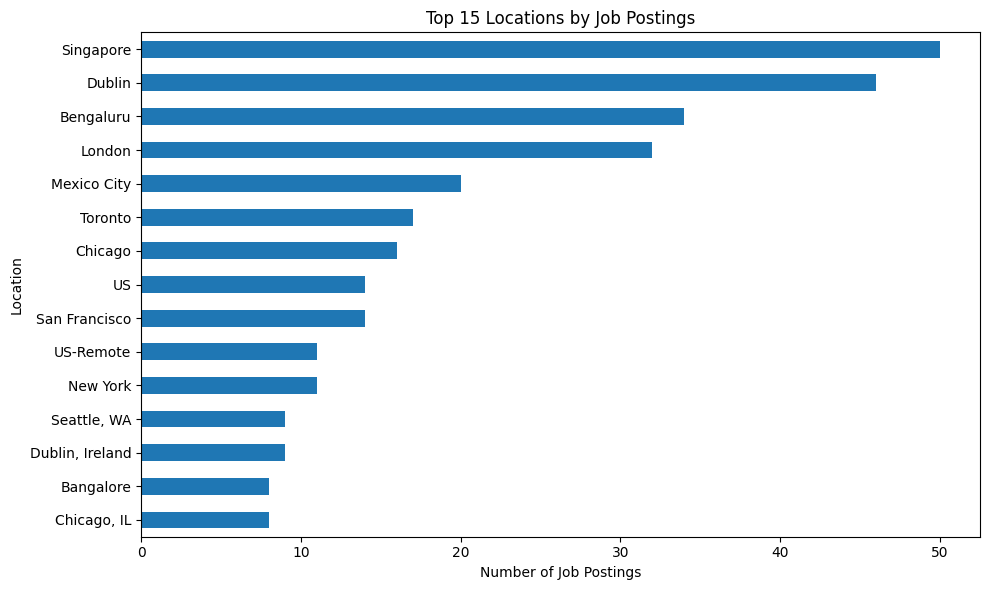

In [20]:
location_counts = (
    df["location"]
    .replace("", "Not Specified")
    .value_counts()
    .head(15)
)

plt.figure(figsize=(10, 6))
location_counts.sort_values().plot(kind="barh")
plt.title("Top 15 Locations by Job Postings")
plt.xlabel("Number of Job Postings")
plt.ylabel("Location")
plt.tight_layout()
plt.show()

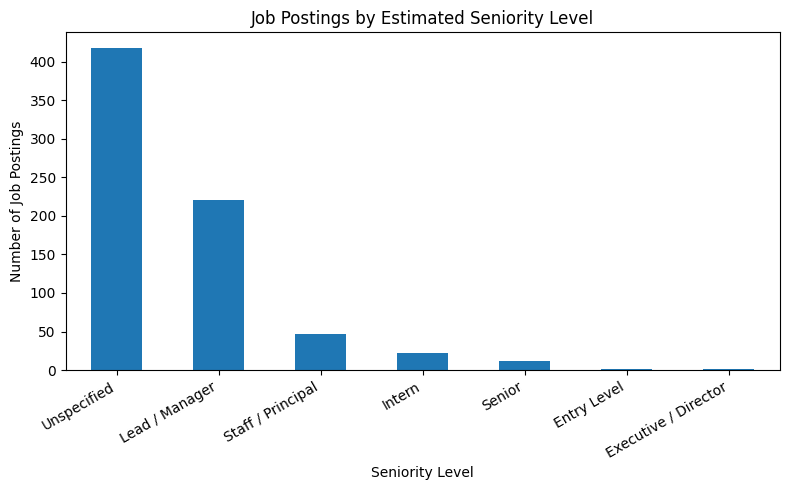

In [21]:
seniority_counts = df["seniority_level"].value_counts()

plt.figure(figsize=(8, 5))
seniority_counts.plot(kind="bar")
plt.title("Job Postings by Estimated Seniority Level")
plt.xlabel("Seniority Level")
plt.ylabel("Number of Job Postings")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

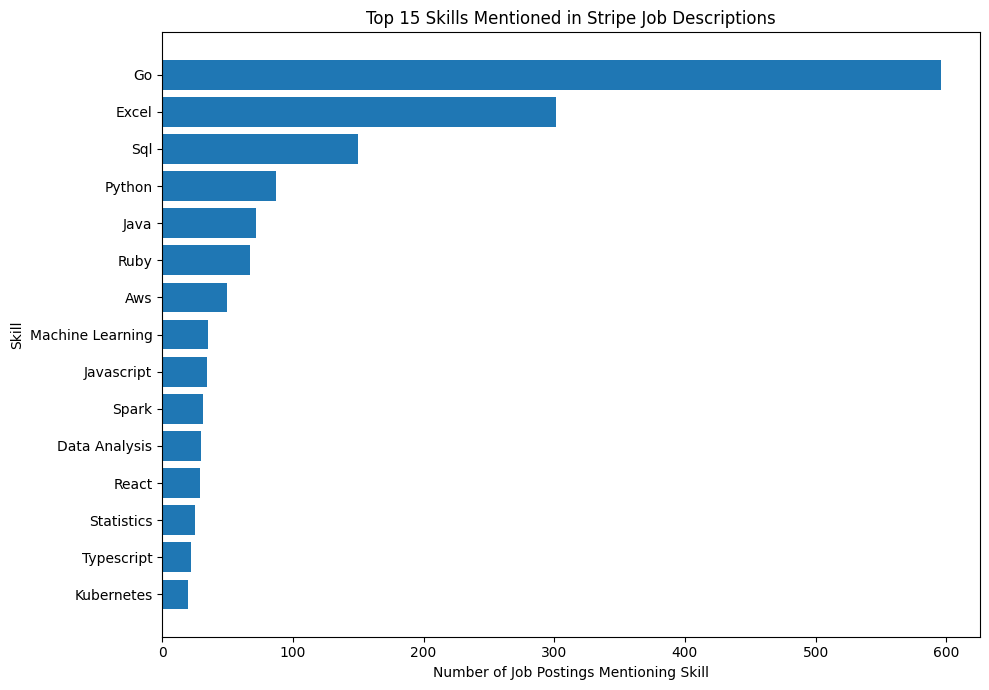

In [22]:
skills_df = pd.read_csv("Stripe_Skill_Summary.csv")

top_skills = skills_df.head(15).sort_values(
    "job_postings_mentioning_skill"
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_skills["skill"],
    top_skills["job_postings_mentioning_skill"]
)
plt.title("Top 15 Skills Mentioned in Stripe Job Descriptions")
plt.xlabel("Number of Job Postings Mentioning Skill")
plt.ylabel("Skill")
plt.tight_layout()
plt.show()

In [23]:
eda_summary = pd.DataFrame({
    "Metric": [
        "Total Job Postings",
        "Unique Job Titles",
        "Unique Departments",
        "Unique Locations"
    ],
    "Value": [
        len(df),
        df["job_title"].nunique(),
        df["department"].nunique(),
        df["location"].nunique()
    ]
})

display(eda_summary)

eda_summary.to_csv("Stripe_EDA_Summary.csv", index=False)

,Metric,Value
0,Total Job Postings,720
1,Unique Job Titles,652
2,Unique Departments,209
3,Unique Locations,273


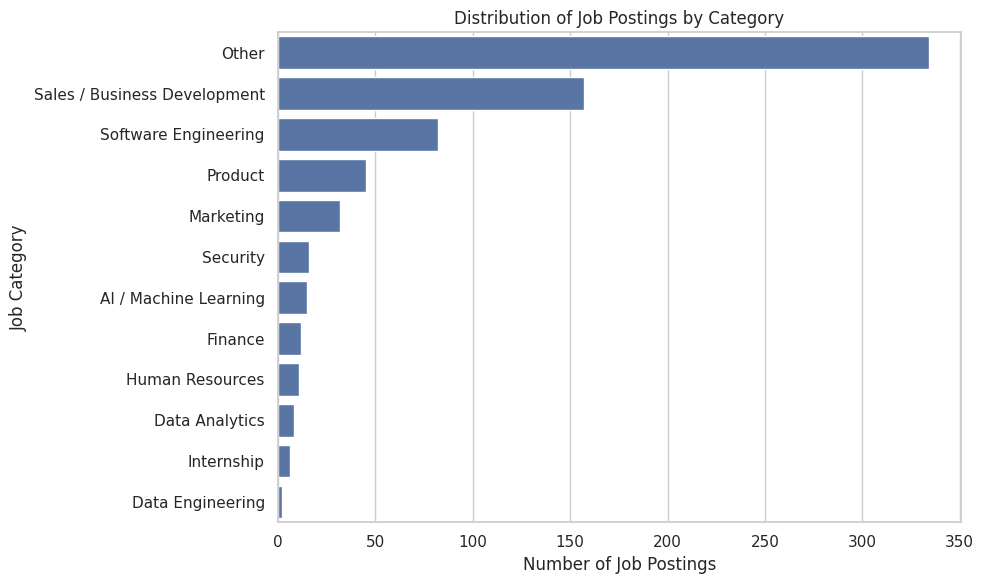

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))
order = df["job_category"].value_counts().index

sns.countplot(
    data=df,
    y="job_category",
    order=order
)

plt.title("Distribution of Job Postings by Category")
plt.xlabel("Number of Job Postings")
plt.ylabel("Job Category")
plt.tight_layout()
plt.show()

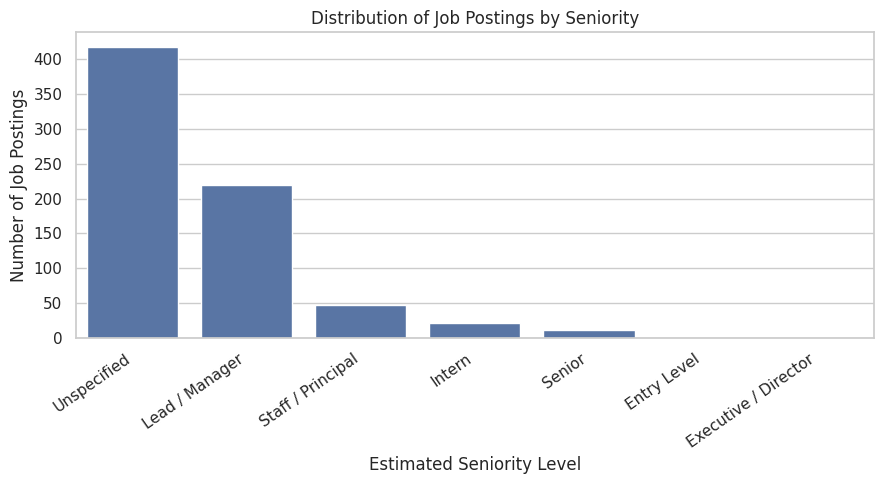

In [25]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="seniority_level",
    order=df["seniority_level"].value_counts().index
)

plt.title("Distribution of Job Postings by Seniority")
plt.xlabel("Estimated Seniority Level")
plt.ylabel("Number of Job Postings")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

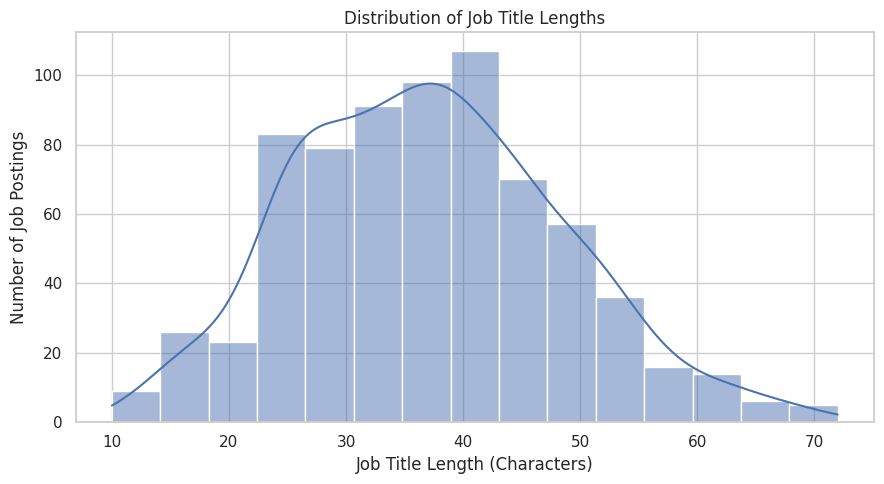

,job_title_length
count,720.000000
mean,37.051389
std,11.389861
min,10.000000
25%,28.000000
50%,37.000000
75%,45.000000
max,72.000000


In [26]:
df["job_title_length"] = df["job_title"].fillna("").str.len()

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="job_title_length",
    bins=15,
    kde=True
)

plt.title("Distribution of Job Title Lengths")
plt.xlabel("Job Title Length (Characters)")
plt.ylabel("Number of Job Postings")
plt.tight_layout()
plt.show()

display(df["job_title_length"].describe())

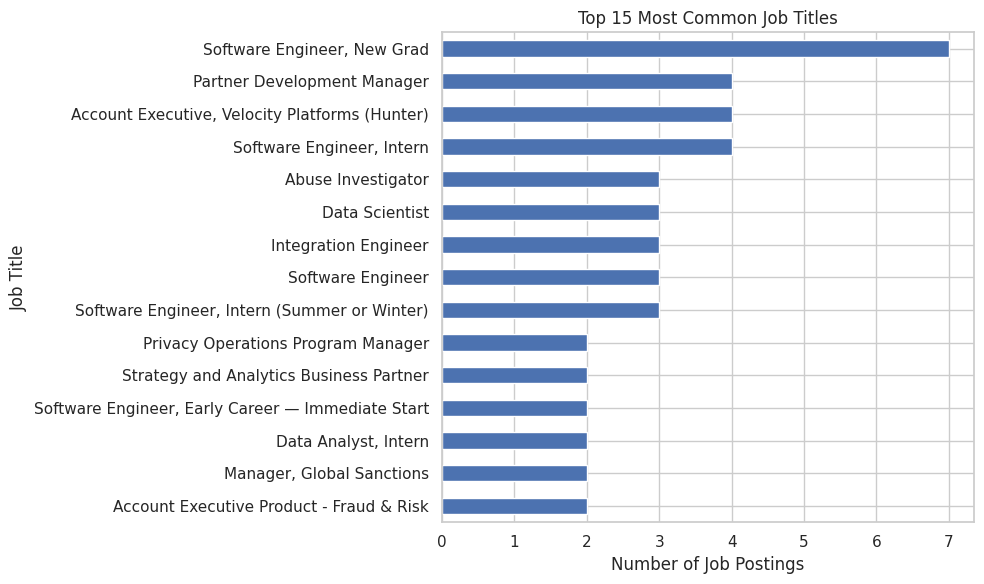

In [27]:
top_titles = df["job_title"].value_counts().head(15)

plt.figure(figsize=(10, 6))
top_titles.sort_values().plot(kind="barh")

plt.title("Top 15 Most Common Job Titles")
plt.xlabel("Number of Job Postings")
plt.ylabel("Job Title")
plt.tight_layout()
plt.show()

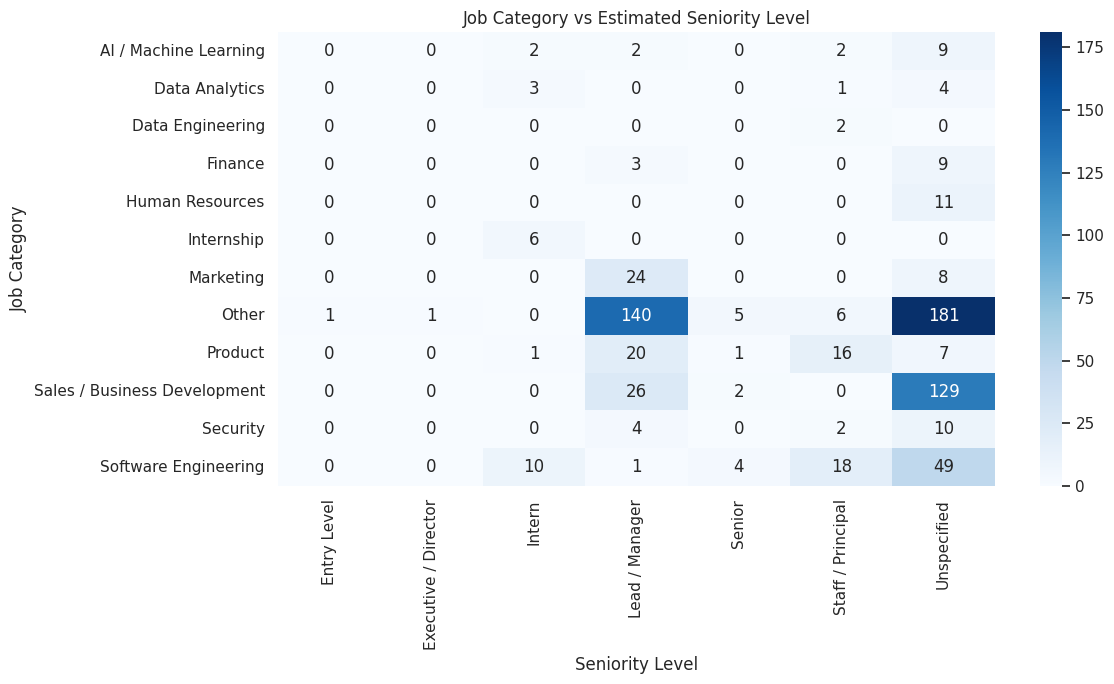

In [28]:
cross_tab = pd.crosstab(
    df["job_category"],
    df["seniority_level"]
)

plt.figure(figsize=(12, 7))

sns.heatmap(
    cross_tab,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Job Category vs Estimated Seniority Level")
plt.xlabel("Seniority Level")
plt.ylabel("Job Category")
plt.tight_layout()
plt.show()

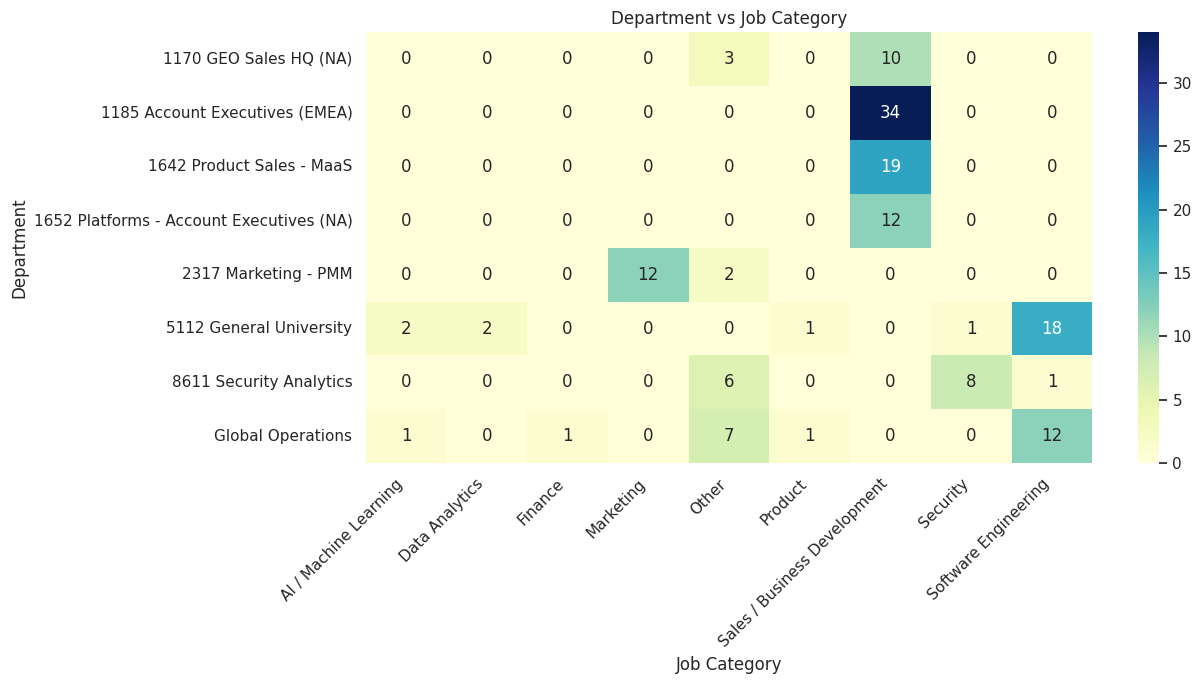

In [29]:
top_departments = df["department"].value_counts().head(8).index

subset = df[df["department"].isin(top_departments)]

department_category = pd.crosstab(
    subset["department"],
    subset["job_category"]
)

plt.figure(figsize=(13, 7))

sns.heatmap(
    department_category,
    annot=True,
    fmt="d",
    cmap="YlGnBu"
)

plt.title("Department vs Job Category")
plt.xlabel("Job Category")
plt.ylabel("Department")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

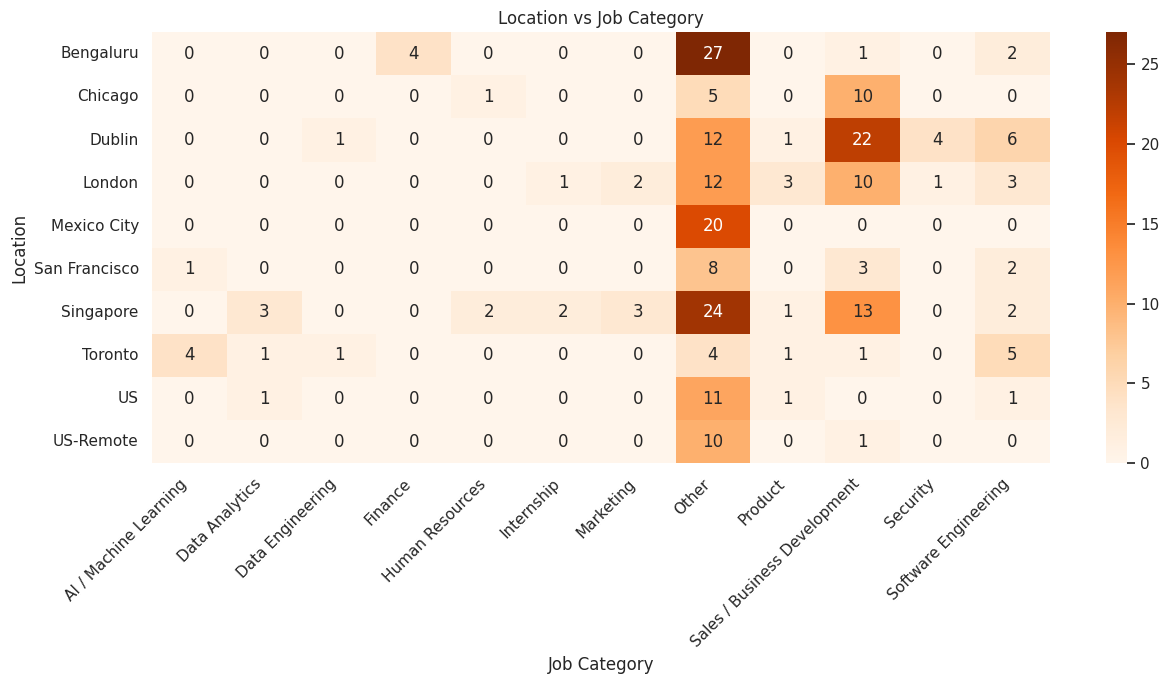

In [30]:
top_locations = df["location"].value_counts().head(10).index

location_subset = df[df["location"].isin(top_locations)]

location_category = pd.crosstab(
    location_subset["location"],
    location_subset["job_category"]
)

plt.figure(figsize=(13, 7))

sns.heatmap(
    location_category,
    annot=True,
    fmt="d",
    cmap="Oranges"
)

plt.title("Location vs Job Category")
plt.xlabel("Job Category")
plt.ylabel("Location")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

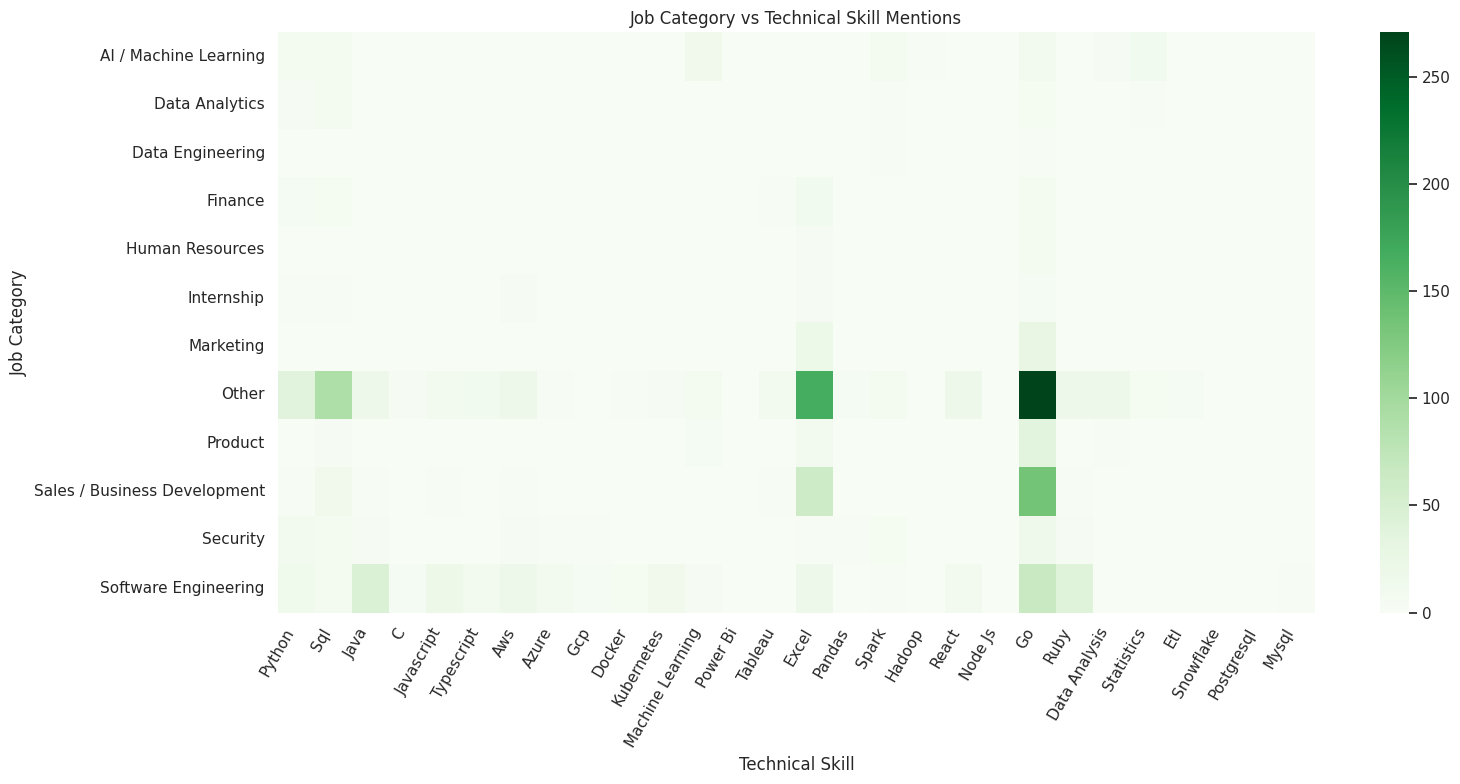

In [31]:
skill_cols = [
    col for col in df.columns
    if col.startswith("skill_")
]

if skill_cols:
    skill_by_category = df.groupby("job_category")[skill_cols].sum()

    skill_by_category.columns = [
        col.replace("skill_", "").replace("_", " ").title()
        for col in skill_by_category.columns
    ]

    plt.figure(figsize=(16, 8))

    sns.heatmap(
        skill_by_category,
        cmap="Greens",
        annot=False
    )

    plt.title("Job Category vs Technical Skill Mentions")
    plt.xlabel("Technical Skill")
    plt.ylabel("Job Category")
    plt.xticks(rotation=60, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No skill indicator columns found. Re-run Step 3.3 first.")

In [32]:
import re
import pandas as pd

# Use the original job description text
descriptions = (
    df["job_description"]
    .fillna("")
    .astype(str)
)

skill_patterns = {
    "Python": r"(?i)(?<!\w)python(?!\w)",
    "SQL": r"(?i)(?<!\w)sql(?!\w)",
    "Java": r"(?i)(?<!\w)java(?!\w)",
    "C++": r"(?i)c\+\+",
    "JavaScript": r"(?i)(?<!\w)javascript(?!\w)",
    "TypeScript": r"(?i)(?<!\w)typescript(?!\w)",
    "AWS": r"(?i)(?<!\w)aws(?!\w)",
    "Azure": r"(?i)(?<!\w)azure(?!\w)",
    "Go": r"(?<!\w)Go(?!\w)",
    "Ruby": r"(?i)(?<!\w)ruby(?!\w)",
    "Excel": r"(?i)(?<!\w)excel(?!\w)",
    "Machine Learning": r"(?i)machine[\s-]+learning",
    "Docker": r"(?i)(?<!\w)docker(?!\w)",
    "Kubernetes": r"(?i)(?<!\w)kubernetes(?!\w)",
    "React": r"(?i)(?<!\w)react(?!\w)",
    "Spark": r"(?i)(?<!\w)spark(?!\w)",
    "Snowflake": r"(?i)(?<!\w)snowflake(?!\w)",
    "PostgreSQL": r"(?i)(?<!\w)postgresql(?!\w)",
    "MySQL": r"(?i)(?<!\w)mysql(?!\w)",
    "Power BI": r"(?i)power\s*bi",
    "Tableau": r"(?i)(?<!\w)tableau(?!\w)",
    "Data Analysis": r"(?i)data analysis",
    "Statistics": r"(?i)(?<!\w)statistics(?!\w)",
    "ETL": r"(?i)(?<!\w)etl(?!\w)",
}

skill_results = []

for skill, pattern in skill_patterns.items():
    count = descriptions.str.contains(
        pattern, regex=True, na=False
    ).sum()

    skill_results.append({
        "skill": skill,
        "job_postings_mentioning_skill": int(count),
        "percentage_of_postings": round(
            count / len(df) * 100, 2
        ) if len(df) else 0
    })

skill_summary_corrected = (
    pd.DataFrame(skill_results)
    .sort_values(
        "job_postings_mentioning_skill",
        ascending=False
    )
    .reset_index(drop=True)
)

display(skill_summary_corrected.head(15))

skill_summary_corrected.to_csv(
    "Stripe_Skill_Summary_Corrected.csv",
    index=False
)

,skill,job_postings_mentioning_skill,percentage_of_postings
0,SQL,145,20.14
1,Go,101,14.03
2,Python,87,12.08
3,Java,70,9.72
4,Ruby,67,9.31
5,Excel,51,7.08
6,Machine Learning,36,5.00
7,AWS,36,5.00
8,JavaScript,34,4.72
9,Data Analysis,30,4.17


In [33]:
other_titles = (
    df.loc[df["job_category"] == "Other", "job_title"]
    .value_counts()
    .head(20)
    .reset_index()
)

other_titles.columns = [
    "job_title",
    "number_of_postings"
]

display(other_titles)

,job_title,number_of_postings
0,Partner Development Manager,4
1,Integration Engineer,3
2,Abuse Investigator,3
3,Customer Success Manager,2
4,Strategy and Analytics Business Partner,2
5,"Solutions Architect, Metronome (Startups)",2
6,Credit Risk Analyst Commercial Underwriter,2
7,People Consultant,2
8,Payments Fraud Investigator,2
9,"Specialist Solutions Architect, Payments",2


In [34]:
print(
    df["job_category"]
    .value_counts()
    .to_string()
)

job_category
Other                           334
Sales / Business Development    157
Software Engineering             82
Product                          45
Marketing                        32
Security                         16
AI / Machine Learning            15
Finance                          12
Human Resources                  11
Data Analytics                    8
Internship                        6
Data Engineering                  2


In [35]:
def classify_job_v2(title):
    title = str(title).lower()

    # Internship
    if any(x in title for x in ["intern", "internship"]):
        return "Internship"

    # Risk, fraud, abuse and trust
    if any(x in title for x in [
        "fraud", "risk analyst", "risk manager", "underwriter",
        "abuse investigator", "sanctions", "trust and safety"
    ]):
        return "Risk / Fraud"

    # Legal and compliance
    if any(x in title for x in [
        "legal", "compliance", "privacy counsel", "regulatory"
    ]):
        return "Legal / Compliance"

    # Customer success and support
    if any(x in title for x in [
        "customer success", "customer support",
        "client success", "technical support"
    ]):
        return "Customer Success / Support"

    # Technical solutions and integration
    if any(x in title for x in [
        "solutions architect", "integration engineer",
        "solutions engineer", "technical account"
    ]):
        return "Technical Solutions"

    # Data and AI
    if any(x in title for x in [
        "data scientist", "machine learning", "ai engineer"
    ]):
        return "AI / Machine Learning"

    if any(x in title for x in [
        "data analyst", "analytics engineer",
        "business intelligence", "strategy and analytics"
    ]):
        return "Data Analytics"

    if any(x in title for x in [
        "data engineer", "data platform"
    ]):
        return "Data Engineering"

    # Software engineering
    if any(x in title for x in [
        "software engineer", "developer", "frontend",
        "front-end", "backend", "back-end", "full stack",
        "full-stack", "integration engineer"
    ]):
        return "Software Engineering"

    # Product
    if any(x in title for x in [
        "product manager", "product designer",
        "product operations"
    ]):
        return "Product"

    # Sales and partnerships
    if any(x in title for x in [
        "sales", "account executive", "business development",
        "partner development"
    ]):
        return "Sales / Business Development"

    # Strategy and operations
    if any(x in title for x in [
        "strategy", "operations", "business operations",
        "program manager"
    ]):
        return "Strategy / Operations"

    # Human resources
    if any(x in title for x in [
        "recruiter", "human resources", "people partner",
        "people consultant"
    ]):
        return "Human Resources"

    # Finance and accounting
    if any(x in title for x in [
        "finance", "accountant", "controller", "treasury"
    ]):
        return "Finance"

    # Marketing and communications
    if any(x in title for x in [
        "marketing", "communications", "public relations"
    ]):
        return "Marketing"

    # Security
    if any(x in title for x in [
        "security engineer", "information security",
        "cybersecurity"
    ]):
        return "Security"

    return "Other"


df["job_category"] = df["job_title"].apply(classify_job_v2)

print("Updated job category counts:")
display(df["job_category"].value_counts().to_frame("Postings"))

print(
    "Percentage still classified as Other:",
    round((df["job_category"].eq("Other").mean() * 100), 2),
    "%"
)

Updated job category counts:


,Postings
job_category,
Sales / Business Development,166
Other,131
Strategy / Operations,89
Software Engineering,83
Technical Solutions,52
Product,43
Risk / Fraud,29
Marketing,27
Internship,22


Percentage still classified as Other: 18.19 %


In [36]:
remaining_other = (
    df.loc[df["job_category"] == "Other", "job_title"]
    .value_counts()
    .head(30)
    .reset_index()
)

remaining_other.columns = ["job_title", "postings"]

display(remaining_other)

,job_title,postings
0,Enterprise Support Specialist,2
1,Abuse Research Engineer,1
2,Accounting AI Solutions Lead,1
3,"Administrative Business Partner, Office of the...",1
4,Android BSP Engineer,1
5,Administrative Coordinator,1
6,"Android Engineer, Terminal OS Platform",1
7,AR Analyst,1
8,"Brand Producer, Link",1
9,"Android Engineer, Terminal - CA",1


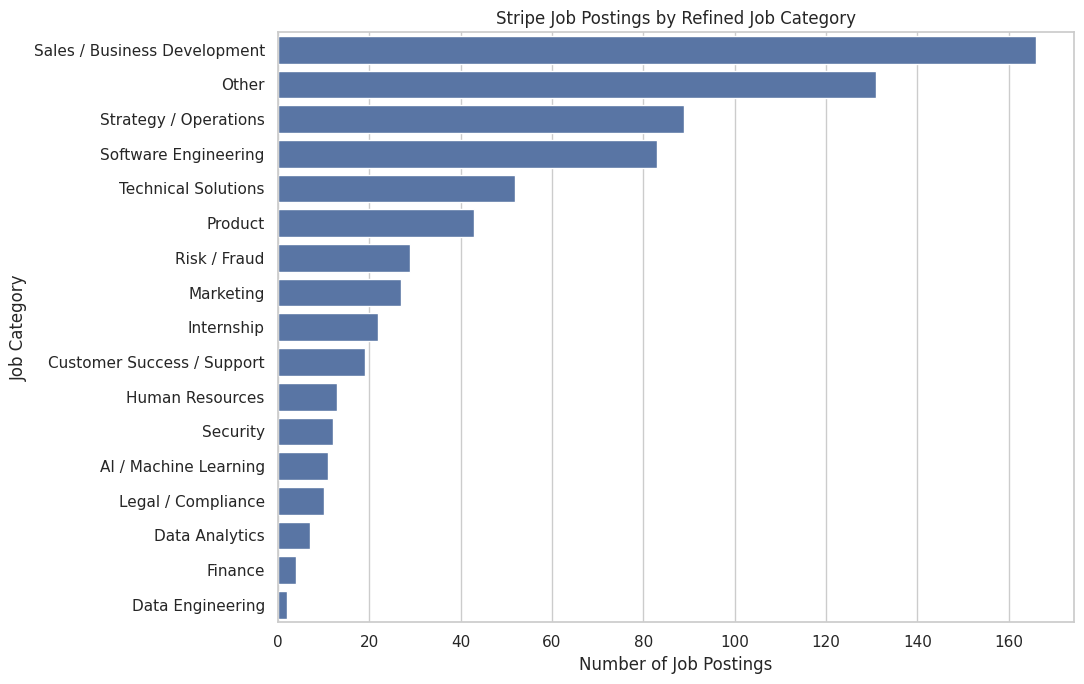

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 7))

order = df["job_category"].value_counts().index

sns.countplot(
    data=df,
    y="job_category",
    order=order
)

plt.title("Stripe Job Postings by Refined Job Category")
plt.xlabel("Number of Job Postings")
plt.ylabel("Job Category")
plt.tight_layout()
plt.show()

In [38]:
# Check remaining job titles classified as Other

other_jobs = df.loc[
    df["job_category"] == "Other",
    "job_title"
]

print("Number of jobs in Other:", len(other_jobs))
print("\nMost common remaining job titles:")

display(other_jobs.value_counts().head(30))

Number of jobs in Other: 131

Most common remaining job titles:


,count
job_title,
Enterprise Support Specialist,2
Abuse Research Engineer,1
Accounting AI Solutions Lead,1
"Administrative Business Partner, Office of the President",1
Android BSP Engineer,1
Administrative Coordinator,1
"Android Engineer, Terminal OS Platform",1
AR Analyst,1
"Brand Producer, Link",1


In [39]:
import inspect

print(inspect.getsource(classify_job_v2))

def classify_job_v2(title):
    title = str(title).lower()

    # Internship
    if any(x in title for x in ["intern", "internship"]):
        return "Internship"

    # Risk, fraud, abuse and trust
    if any(x in title for x in [
        "fraud", "risk analyst", "risk manager", "underwriter",
        "abuse investigator", "sanctions", "trust and safety"
    ]):
        return "Risk / Fraud"

    # Legal and compliance
    if any(x in title for x in [
        "legal", "compliance", "privacy counsel", "regulatory"
    ]):
        return "Legal / Compliance"

    # Customer success and support
    if any(x in title for x in [
        "customer success", "customer support",
        "client success", "technical support"
    ]):
        return "Customer Success / Support"

    # Technical solutions and integration
    if any(x in title for x in [
        "solutions architect", "integration engineer",
        "solutions engineer", "technical account"
    ]):
        return "Technical Soluti

In [40]:

def classify_job_v2(title):
    title = str(title).lower()

    # Internship
    if any(x in title for x in ["intern", "internship"]):
        return "Internship"

    # Risk, fraud, abuse and trust
    if any(x in title for x in [
        "fraud", "risk analyst", "risk manager", "underwriter",
        "abuse", "sanctions", "trust and safety", "credit risk"
    ]):
        return "Risk / Fraud"

    # Legal and compliance
    if any(x in title for x in [
        "legal", "counsel", "compliance", "regulatory"
    ]):
        return "Legal / Compliance"

    # Customer success and support
    if any(x in title for x in [
        "customer success", "customer support", "client success",
        "technical support", "enterprise support",
        "critical support", "escalation"
    ]):
        return "Customer Success / Support"

    # Technical solutions and integration
    if any(x in title for x in [
        "solutions architect", "integration engineer",
        "solutions engineer", "technical account",
        "business systems architect", "business value consultant"
    ]):
        return "Technical Solutions"

    # Data science and AI
    if any(x in title for x in [
        "data scientist", "data science", "machine learning",
        "ai engineer", "artificial intelligence"
    ]):
        return "AI / Machine Learning"

    # Data analytics
    if any(x in title for x in [
        "data analyst", "analytics engineer",
        "business intelligence", "strategy and analytics",
        "ar analyst", "accounting analyst"
    ]):
        return "Data Analytics"

    # Data engineering
    if any(x in title for x in [
        "data engineer", "data platform"
    ]):
        return "Data Engineering"

    # Software engineering
    if any(x in title for x in [
        "software engineer", "android engineer", "android bsp",
        "engineer", "developer", "frontend", "front-end",
        "backend", "back-end", "full stack", "full-stack"
    ]):
        return "Software Engineering"

    # Product and design
    if any(x in title for x in [
        "product manager", "product designer", "product operations"
    ]):
        return "Product"

    if any(x in title for x in [
        "designer", "design engineer", "brand producer",
        "editorial director", "creative"
    ]):
        return "Marketing"

    # Sales and partnerships
    if any(x in title for x in [
        "sales", "account executive", "business development",
        "partner development", "strategic alliance",
        "commercial lead", "deal strategist", "deal pricing",
        "engagement manager"
    ]):
        return "Sales / Business Development"

    # Strategy and operations
    if any(x in title for x in [
        "strategy", "operations", "business operations",
        "program manager", "administrative coordinator",
        "administrative business partner"
    ]):
        return "Strategy / Operations"

    # Human resources
    if any(x in title for x in [
        "recruiter", "human resources", "people partner",
        "people consultant", "people consultant",
        "employment", "talent"
    ]):
        return "Human Resources"

    # Finance and accounting
    if any(x in title for x in [
        "finance", "accountant", "accounting", "controller",
        "treasury", "capital markets", "fx specialist",
        "pricing", "investments"
    ]):
        return "Finance"

    # Marketing and communications
    if any(x in title for x in [
        "marketing", "communications", "public relations",
        "demand generation", "brand"
    ]):
        return "Marketing"

    # Security
    if any(x in title for x in [
        "security engineer", "information security",
        "cybersecurity", "security"
    ]):
        return "Security"

    return "Other"


# Reclassify job postings
df["job_category"] = df["job_title"].apply(classify_job_v2)

# Display updated category counts
category_counts = (
    df["job_category"]
    .value_counts()
    .rename_axis("job_category")
    .reset_index(name="job_postings")
)

display(category_counts)

print("Total postings:", len(df))
print("Remaining Other postings:",
      (df["job_category"] == "Other").sum())


,job_category,job_postings
0,Sales / Business Development,173
1,Software Engineering,128
2,Strategy / Operations,83
3,Other,59
4,Technical Solutions,54
5,Product,43
6,Risk / Fraud,38
7,Marketing,35
8,Customer Success / Support,23
9,Internship,22


Total postings: 720
Remaining Other postings: 59


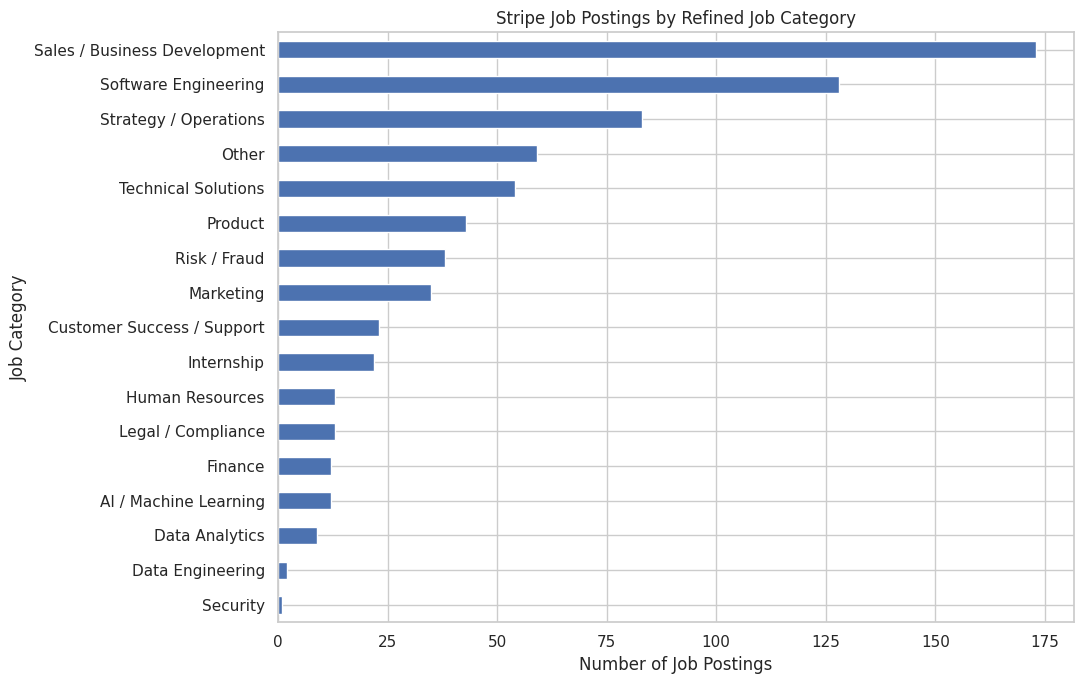

In [41]:

import matplotlib.pyplot as plt

category_counts = df["job_category"].value_counts().sort_values()

plt.figure(figsize=(11, 7))
category_counts.plot(kind="barh")

plt.title("Stripe Job Postings by Refined Job Category")
plt.xlabel("Number of Job Postings")
plt.ylabel("Job Category")
plt.tight_layout()
plt.show()


In [42]:

df.to_csv("Stripe_Job_Postings_Featured.csv", index=False)

print("Updated featured dataset saved successfully.")
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Missing job categories:", df["job_category"].isna().sum())


Updated featured dataset saved successfully.
Rows: 720
Columns: 43
Missing job categories: 0


In [43]:

# Save the updated DataFrame
df.to_csv("Stripe_Job_Postings_Featured.csv", index=False)

# Download the updated CSV to your computer
from google.colab import files
files.download("Stripe_Job_Postings_Featured.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>